In [31]:
# imports
import time

import pandas as pd
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, RandomForestClassifier
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score, precision_score, mean_absolute_error, mean_squared_error

In [28]:
# load data
df = pd.read_csv("data/titanic.csv")

# describe
df.describe()





,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


# Interpretation der statistischen Kennzahlen auf Basis der bereitgestellten Datensätze
- 891 Datensätze für Passagiere
- von einer kleinen Teilmenge von Passagieren ist das Alter unbekannt (ca. 177)
- ca. 38% haben tatsächlich überlebt
- Die meisten Passagiere fahren mit Klasse 3
- Durchschnittsalter ca. 30 Jahre
- Die meisten Passagiere kommen ohne Familienangehörige, ca. 60%
- Die Passagiere bezahlen durchschnittlich 32 {currency} für ihr Ticket
- 1,6% Passagiere hätten nicht bezahlt
- Alle Babys unter einem Jahr haben überlebt




In [29]:
%%sql
SELECT COUNT(*), Pclass FROM df GROUP BY Pclass

UsageError: Cell magic `%%sql` not found.


In [ ]:
df = pd.read_csv("data/titanic.csv")

# Überlebensrate nach Klasse

<Axes: xlabel='Pclass', ylabel='Survived'>

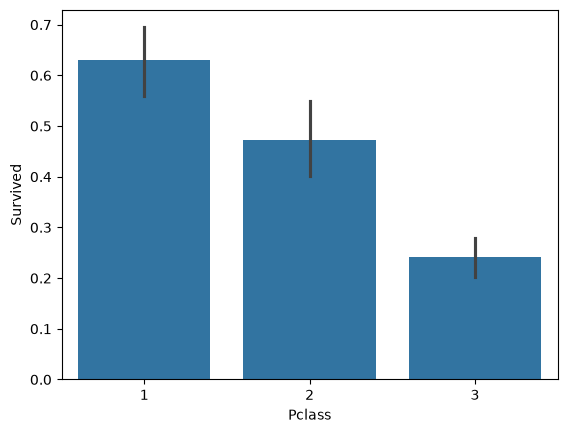

In [ ]:
sns.barplot(data=df, x="Pclass", y="Survived")

# Überlebensrate geordnet nach Altersgruppe

<Axes: xlabel='AgeGroup', ylabel='Survived'>

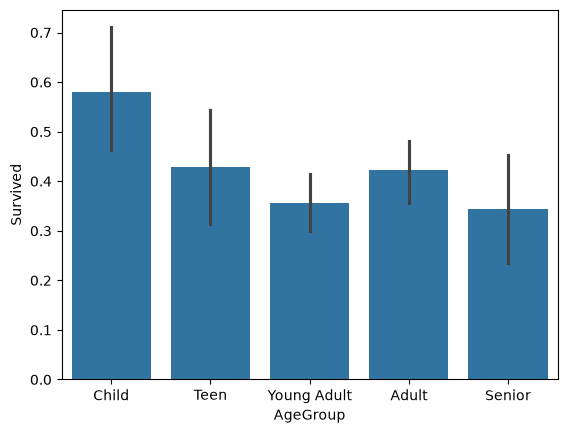

In [ ]:
df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 30, 50, 100],
                        labels=["Child", "Teen", "Young Adult", "Adult", "Senior"])
sns.barplot(data=df, x="AgeGroup", y="Survived")

# Überlebensrate nach Geschlecht

<Axes: xlabel='Sex', ylabel='Survived'>

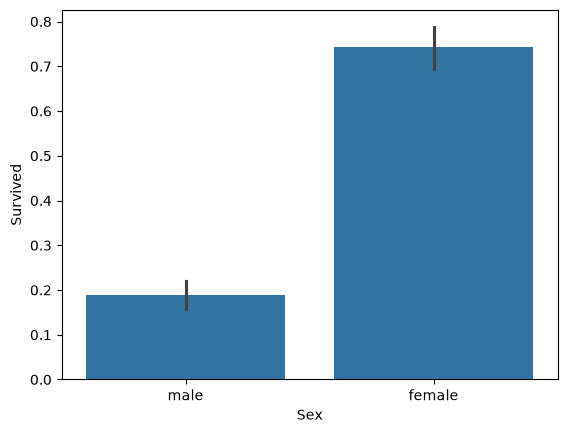

In [ ]:
sns.barplot(data=df, x="Sex",  y="Survived")

# Überlebensrate nach Familiengröße

<Axes: xlabel='FamilySize', ylabel='Survived'>

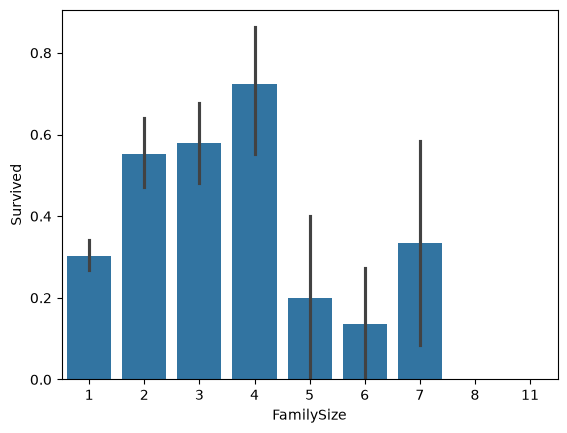

In [ ]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
sns.barplot(data=df, x="FamilySize", y="Survived")

In [ ]:
df = pd.read_csv("data/titanic.csv")

#Ausgewählte Features
X = [['Sex'], ['Fare']]
y = ['Survived']

#df['PassengerId'] = df['PassengerId'].astype(str)
#id_encoded = pd.get_dummies(df, columns=['PassengerId'], dtype=int)

sex_encoded = pd.get_dummies(df, columns=['Sex'], dtype=int)

print(sex_encoded.head())

  PassengerId  Survived  Pclass  \
0           1         0       3   
1           2         1       1   
2           3         1       3   
3           4         1       1   
4           5         0       3   

                                                Name   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  38.0      1      0   
2                             Heikkinen, Miss. Laina  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  35.0      1      0   
4                           Allen, Mr. William Henry  35.0      0      0   

             Ticket     Fare Cabin Embarked  Sex_female  Sex_male  
0         A/5 21171   7.2500   NaN        S           0         1  
1          PC 17599  71.2833   C85        C           1         0  
2  STON/O2. 3101282   7.9250   NaN        S           1         0  
3            113803  53.1000  C123        S           1     

In [ ]:
# load data from csv
df = pd.read_csv("data/titanic.csv")


In [ ]:
# features
X = df[['Sex', 'Fare', 'Age', 'Pclass']].copy()
X['Sex'] = X['Sex'].map({'male': 0, 'female': 1})
X['Age'] = X['Age'].fillna(X['Age'].median())

# target
y = df["Survived"]

In [ ]:
# split training data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# choose models
models = [
    LinearRegression(),
    DecisionTreeRegressor(),
    RandomForestRegressor(),
    GradientBoostingRegressor(),
    SVR(),
]

results = {}

for model in models:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_class = y_pred >= 0.5   # survived if prediction >= 0.5
    results[type(model).__name__] = {
        "Accuracy": accuracy_score(y_test, y_pred_class),
        "Precision": precision_score(y_test, y_pred_class),
        "Mean Absolute Error": mean_absolute_error(y_test, y_pred),
        "Mean Squared Error": mean_squared_error(y_test, y_pred),
    }

results = pd.DataFrame(results).T
results


,Accuracy,Precision,Mean Absolute Error,Mean Squared Error
LinearRegression,0.787709,0.757143,0.287746,0.137168
DecisionTreeRegressor,0.754190,0.678571,0.260486,0.244114
RandomForestRegressor,0.787709,0.750000,0.244238,0.152462
GradientBoostingRegressor,0.810056,0.822581,0.257216,0.131899
SVR,0.648045,0.739130,0.360203,0.243960


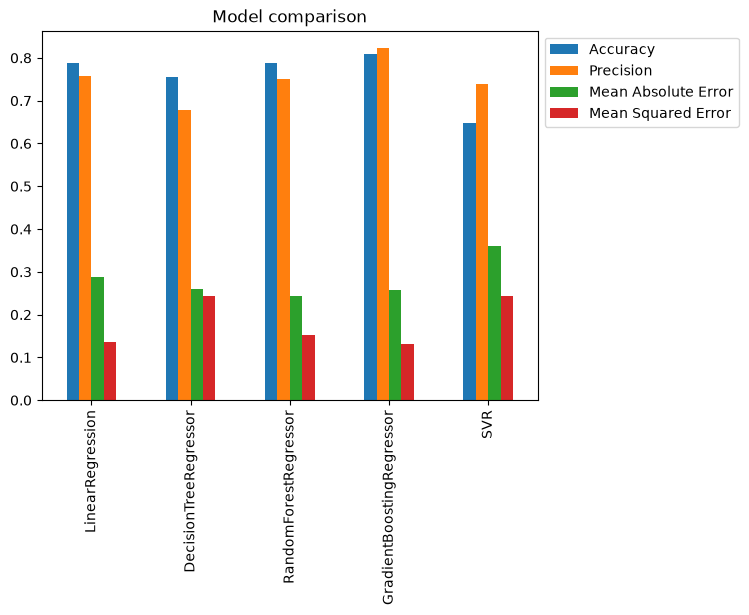

In [ ]:
# compare models
results.plot.bar()
plt.title("Model comparison")
plt.legend(bbox_to_anchor=(1, 1))
plt.show()


## Hyperparameteroptimierung: GridSearchCV

`RandomForestClassifier` wurden auf dem Titanic-Datensatz trainiert und mit `GridSearchCV` optimiert


## 1. Daten laden und vorbereiten


In [ ]:
df = pd.read_csv("data/titanic.csv")

# Kategorisches Merkmal in Zahlen umwandeln (male = 0, female = 1)
X = df[["Sex", "Fare", "Age"]].copy()
X["Sex"] = X["Sex"].map({"male": 0, "female": 1}).astype(int)
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training: {X_train.shape[0]} Zeilen, Test: {X_test.shape[0]} Zeilen")
print(f"Fehlende Age-Werte im Training: {X_train['Age'].isna().sum()}")


Training: 712 Zeilen, Test: 179 Zeilen
Fehlende Age-Werte im Training: 137


## 2. GridSearchCV

Das Grid enthält `3 x 3 x 3 x 2 = 54` Kombinationen. Mit 5-facher Cross-Validation werden
also `54 x 5 = 270` Modelle trainiert.


In [ ]:
param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 10, 12],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"],
}

rfc = RandomForestClassifier(random_state=42)

grid = GridSearchCV(
    estimator=rfc,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
)

start = time.perf_counter()
grid.fit(X_train, y_train)
search_time = time.perf_counter() - start

print(f"Anzahl Kombinationen: {len(grid.cv_results_['params'])}")
print(f"Gesamte GridSearch-Zeit: {search_time:.2f} s")
print(f"Beste Parameter: {grid.best_params_}")
print(f"Beste CV-Accuracy: {grid.best_score_:.4f}")


Fitting 5 folds for each of 54 candidates, totalling 270 fits


Anzahl Kombinationen: 54
Gesamte GridSearch-Zeit: 103.54 s
Beste Parameter: {'criterion': 'gini', 'max_depth': 12, 'min_samples_split': 10, 'n_estimators': 100}
Beste CV-Accuracy: 0.8006


In [ ]:
results = pd.DataFrame(grid.cv_results_).copy()

# Parameter in eigene Spalten aufteilen
results = pd.concat([results, pd.DataFrame(results["params"].tolist())], axis=1)

results["max_depth_str"] = results["max_depth"].apply(
    lambda v: "None" if pd.isna(v) else str(int(v))
)
results["max_depth_num"] = results["max_depth"].apply(
    lambda v: 0 if pd.isna(v) else int(v)
)
results["label"] = results.apply(
    lambda r: f"n={r['n_estimators']}, d={r['max_depth_str']}, "
              f"split={r['min_samples_split']}, {r['criterion']}",
    axis=1,
)

results[["rank_test_score", "mean_test_score", "std_test_score",
         "mean_fit_time", "params"]].sort_values("rank_test_score").head(10)


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
24,1,0.800640,0.031075,0.371140,"{'criterion': 'gini', 'max_depth': 12, 'min_sa..."
16,2,0.799222,0.023608,1.335348,"{'criterion': 'gini', 'max_depth': 10, 'min_sa..."
15,3,0.797804,0.024071,0.440684,"{'criterion': 'gini', 'max_depth': 10, 'min_sa..."
3,4,0.796435,0.028482,0.366092,"{'criterion': 'gini', 'max_depth': None, 'min_..."
33,5,0.796435,0.033603,0.523362,"{'criterion': 'entropy', 'max_depth': None, 'm..."
25,6,0.796415,0.028661,1.050214,"{'criterion': 'gini', 'max_depth': 12, 'min_sa..."
42,7,0.796395,0.032698,0.341581,"{'criterion': 'entropy', 'max_depth': 10, 'min..."
43,8,0.795016,0.032628,1.237762,"{'criterion': 'entropy', 'max_depth': 10, 'min..."
10,9,0.795006,0.029491,1.357675,"{'criterion': 'gini', 'max_depth': 10, 'min_sa..."
17,9,0.795006,0.025558,2.083392,"{'criterion': 'gini', 'max_depth': 10, 'min_sa..."


### 2.1 Top-10 Kombinationen


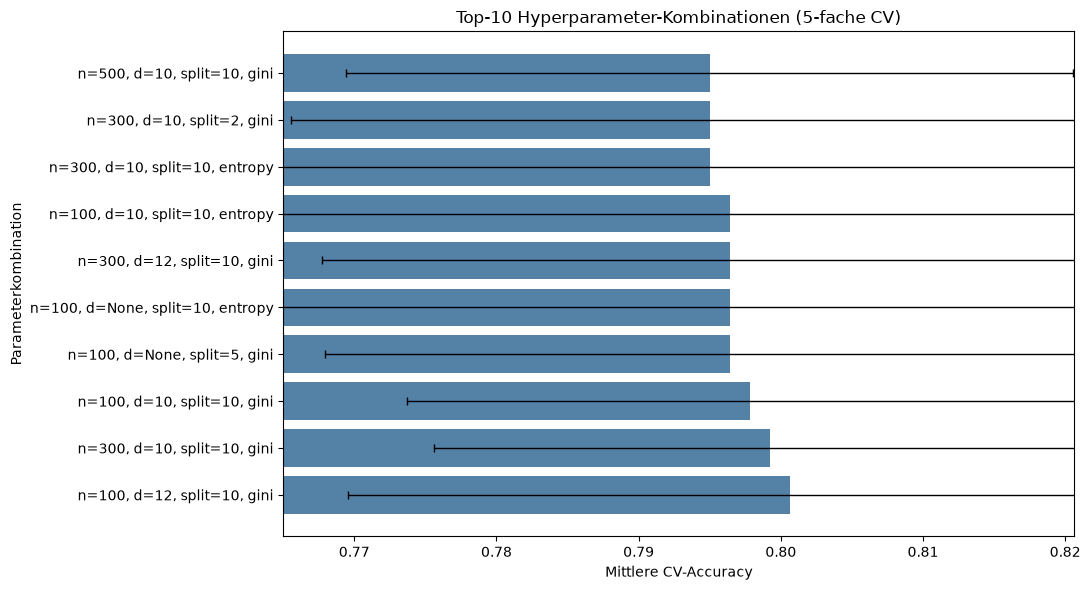

In [32]:
top10 = results.nsmallest(10, "rank_test_score").sort_values("mean_test_score")
order = top10["label"].tolist()

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(
    data=top10, x="mean_test_score", y="label",
    order=order, color="steelblue", ax=ax,
)
ax.errorbar(
    x=top10["mean_test_score"], y=np.arange(len(top10)),
    xerr=top10["std_test_score"], fmt="none",
    ecolor="black", capsize=3, linewidth=1,
)
ax.set_xlim(top10["mean_test_score"].min() - 0.03,
            top10["mean_test_score"].max() + 0.02)
ax.set_xlabel("Mittlere CV-Accuracy")
ax.set_ylabel("Parameterkombination")
ax.set_title("Top-10 Hyperparameter-Kombinationen (5-fache CV)")
plt.tight_layout()
plt.show()


### 2.2 Heatmap: `max_depth` x `n_estimators`


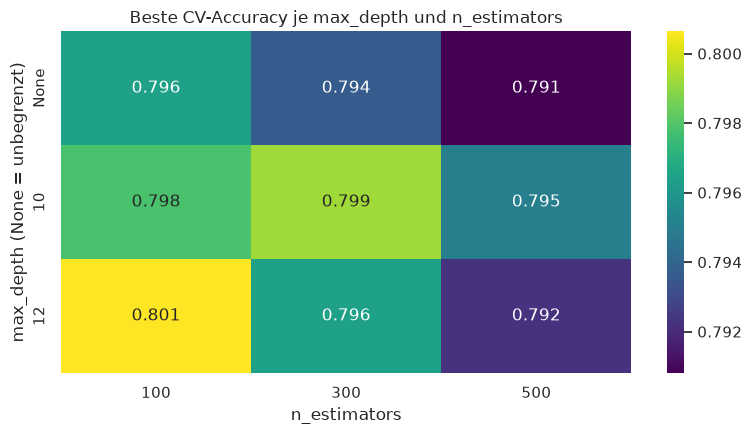

In [ ]:
pivot = results.pivot_table(
    index="max_depth_str",
    columns="n_estimators",
    values="mean_test_score",
    aggfunc="max",
).reindex(["None", "10", "12"])

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", ax=ax)
ax.set_title("Beste CV-Accuracy je max_depth und n_estimators")
ax.set_xlabel("n_estimators")
ax.set_ylabel("max_depth (None = unbegrenzt)")
plt.tight_layout()
plt.show()


In [ ]:
df = pd.read_csv("data/titanic.csv")

df.loc[df['Sex'] == "male", 'Sex'] = "0"
df.loc[df['Sex'] == "female", 'Sex'] = "1"

X = df[['Sex', 'Fare', 'Age']]
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rfc = RandomForestClassifier()

#rfc.fit(X_train, y_train)
#y_pred = rfc.predict(X_test)
#accuracy = accuracy_score(y_test, y_pred)

param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 10, 12],
    "min_samples_split": [2, 5, 10],
    "criterion": ["gini", "entropy"]
}

grid = GridSearchCV(
    estimator=rfc,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(f"Beste Param: {grid.best_params_}")
print(f"Bester CV: {grid.best_score_:.4f}")

best_model = grid.best_estimator_
best_acc = best_model.score(X_test, y_test)

print(f"Acc: {best_acc:.4f}")

Beste Param: {'criterion': 'entropy', 'max_depth': 12, 'min_samples_split': 10, 'n_estimators': 500}
Bester CV: 0.8006
Acc: 0.7709
